# A 1-D mesh

Goal: Create a 1-D mesh and read its cells, faces and ghost cells.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from zoomy_core.mesh import LSQMesh

mesh = LSQMesh.create_1d(domain=(0.0, 1.0), n_inner_cells=8)
n = mesh.n_inner_cells

In [2]:
print("cells", mesh.n_cells, "= inner", n, "+ ghost", mesh.n_cells - n)
print("faces", mesh.n_faces, "of which boundary", mesh.n_boundary_faces)
print("centers", mesh.cell_centers[0, :n])
print("volumes", mesh.cell_volumes[:n])
print("face x ", mesh.face_centers[:, 0])
print("face_cells\n", mesh.face_cells)
print("ghost of", dict(zip(mesh.boundary_conditions_sorted_names, mesh.boundary_face_ghosts.tolist())))

cells 10 = inner 8 + ghost 2
faces 9 of which boundary 2
centers [0.0625 0.1875 0.3125 0.4375 0.5625 0.6875 0.8125 0.9375]
volumes [0.125 0.125 0.125 0.125 0.125 0.125 0.125 0.125]
face x  [0.    0.125 0.25  0.375 0.5   0.625 0.75  0.875 1.   ]
face_cells
 [[0 0 1 2 3 4 5 6 7]
 [8 1 2 3 4 5 6 7 9]]
ghost of {'left': 8, 'right': 9}


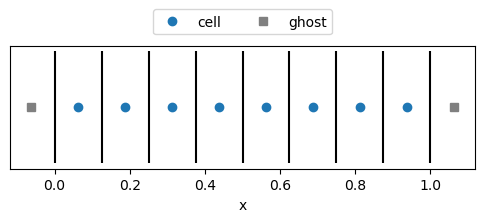

In [3]:
fig, ax = plt.subplots(figsize=(6, 1.6))
ax.vlines(mesh.face_centers[:, 0], -0.2, 0.2, color="k")
ax.plot(mesh.cell_centers[0, :n], np.zeros(n), "o", label="cell")
ax.plot(mesh.cell_centers[0, n:], np.zeros(2), "s", color="gray", label="ghost")
ax.set_yticks([])
ax.set_xlabel("x")
ax.legend(ncol=2, loc="upper center", bbox_to_anchor=(0.5, 1.35))
plt.show()

In [4]:
assert np.isclose(mesh.cell_volumes[:n].sum(), 1.0)
assert np.allclose(mesh.cell_volumes[:n], 1.0 / n)
assert np.array_equal(mesh.face_cells[:, 1:-1], [np.arange(n - 1), np.arange(1, n)])
assert set(mesh.boundary_face_ghosts) == {n, n + 1}